# Initial EDA — German Credit Data
This file conducts initial analysis on the raw data.
Insights on the raw data seen here inform feature engineering that follows. 
To prevent leakage, no analysis is conducted on relationships between features and the target since a train test split has not been done yet.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from load_data import load_data

sns.set_theme(style="whitegrid")
df = load_data()
df.head()

,checking,duration,history,purpose,amount,savings,employment,installment_rate,personal_status,debtors,...,property,age,other_plans,housing,n_credits,job,n_dependents,telephone,foreign_worker,default
0,<0,6,critical,radio/tv,1169,unknown/none,>=7y,4,male single,none,...,real estate,67,none,own,2,skilled,1,yes,yes,0
1,0-200,48,existing paid,radio/tv,5951,<100,1-4y,2,female div/sep/mar,none,...,real estate,22,none,own,1,skilled,1,no,yes,1
2,none,12,critical,education,2096,<100,4-7y,2,male single,none,...,real estate,49,none,own,1,unskilled res,2,no,yes,0
3,<0,42,existing paid,furniture,7882,<100,4-7y,2,male single,guarantor,...,savings/insurance,45,none,free,1,skilled,2,no,yes,0
4,<0,24,past delay,new car,4870,<100,1-4y,3,male single,none,...,none,53,none,free,2,skilled,2,no,yes,1


## 1. Structure and data quality

In [2]:
print("Shape:", df.shape)
# Each row is a loan applicant/credit applicant and there are a 1000 such rows with 20 descriptors
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df.dtypes.value_counts()

Shape: (1000, 21)
Missing values: 0
Duplicate rows: 0


str      13
int64     8
Name: count, dtype: int64

## 2. Target
`default` = 1 for bad credit (raw code 2). Imbalanced 70/30, so accuracy is misleading — we use AUC, precision/recall
and stratified splits throughout.

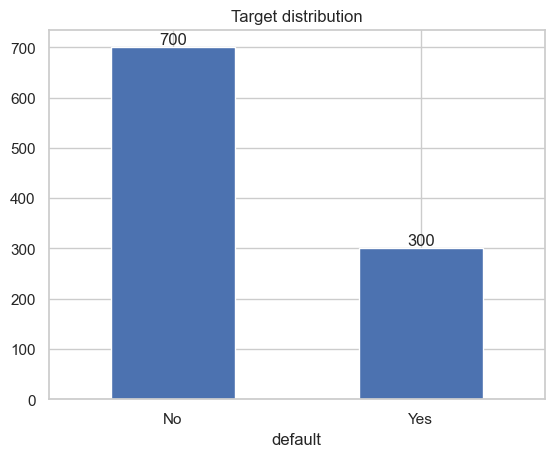

Default rate: 30.0%


In [3]:
counts = df["default"].value_counts().rename({0: "No", 1: "Yes"})
ax = counts.plot.bar(rot=0, title="Target distribution")
ax.bar_label(ax.containers[0])
plt.show()
print(f"Default rate: {df['default'].mean():.1%}")

## 3. Numerical variables

In [4]:
# Understanding the distributions, numerically and then visually
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
duration,1000.0,20.90,12.06,4.0,12.0,18.0,24.00,72.0
amount,1000.0,3271.26,2822.74,250.0,1365.5,2319.5,3972.25,18424.0
installment_rate,1000.0,2.97,1.12,1.0,2.0,3.0,4.00,4.0
residence_since,1000.0,2.84,1.10,1.0,2.0,3.0,4.00,4.0
age,1000.0,35.55,11.38,19.0,27.0,33.0,42.00,75.0
n_credits,1000.0,1.41,0.58,1.0,1.0,1.0,2.00,4.0
n_dependents,1000.0,1.16,0.36,1.0,1.0,1.0,1.00,2.0
default,1000.0,0.30,0.46,0.0,0.0,0.0,1.00,1.0


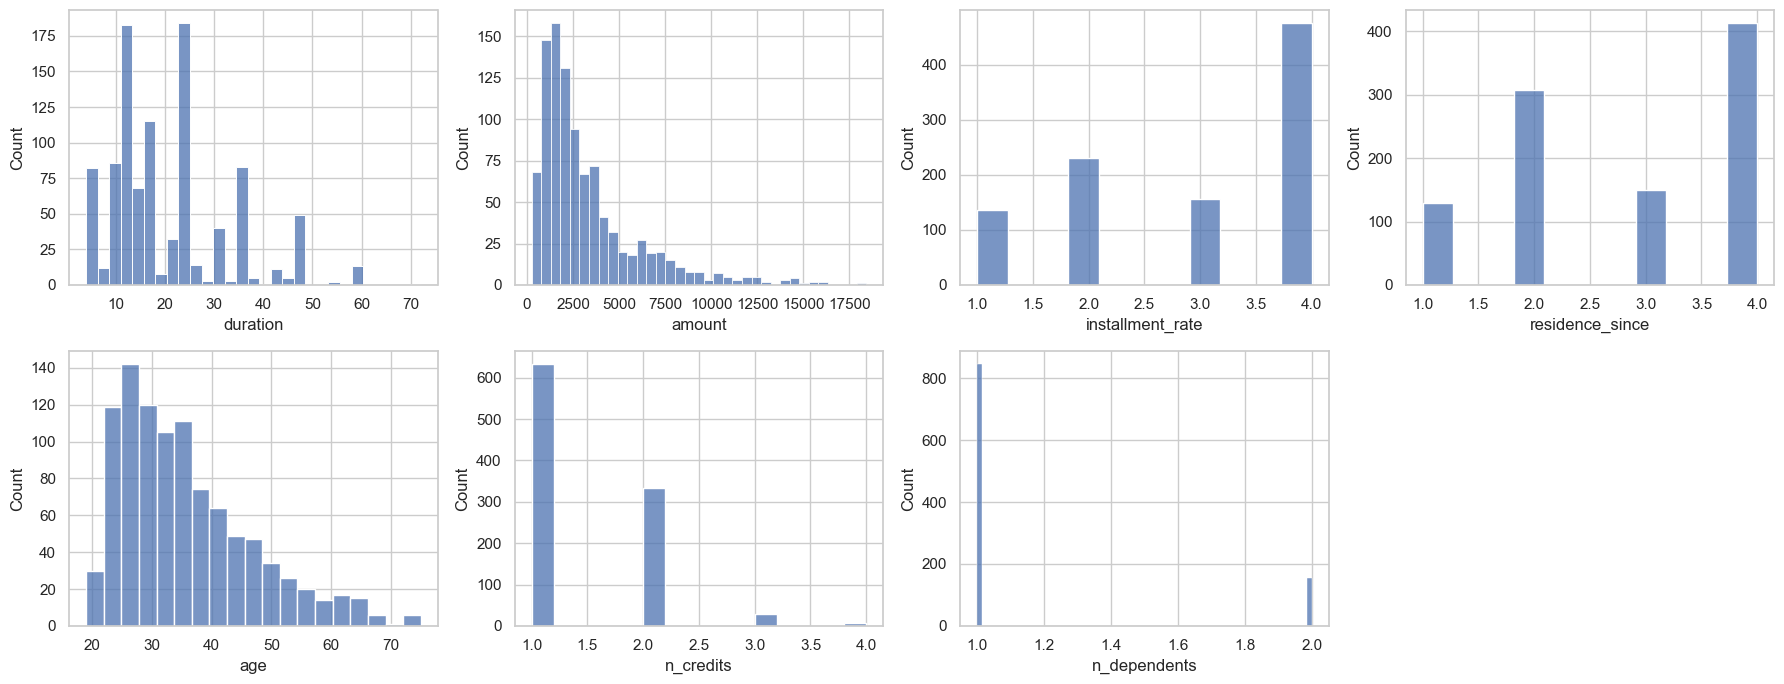

,skew
duration,1.09
amount,1.95
installment_rate,-0.53
residence_since,-0.27
age,1.02
n_credits,1.27
n_dependents,1.91


In [ ]:
num_raw = ["duration", "amount", "installment_rate", "residence_since", "age", "n_credits", "n_dependents"]
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.flat, num_raw):
    sns.histplot(data=df, x=col, ax=ax)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()
df[num_raw].skew().round(2).rename("skew").to_frame()
# significant right skew in the amount. These are not outliers, but fewer high ticket loans.
# a log transform will be used before modelling to address this skew. 
# skew value for n_dependents is also high but because there are only two possible values.

# duration and age also show right skew but are close to the standard practice high skew thresholds (>1).
# initial design will not transform these variables, which could be revisited if needed.

## 4. Categorical variables

In [7]:
cat_raw = df.select_dtypes(exclude="number").columns.tolist()

for col in cat_raw:
    counts = df[col].value_counts(dropna=False)
    tbl = pd.DataFrame({"count": counts, "percentage": (counts / len(df) * 100).round(1)})
    print(f"\n{col} ({df[col].nunique()} levels)")
    display(tbl)


checking (4 levels)


,count,percentage
checking,,
none,394,39.4
<0,274,27.4
0-200,269,26.9
>=200,63,6.3



history (5 levels)


,count,percentage
history,,
existing paid,530,53.0
critical,293,29.3
past delay,88,8.8
all paid (this bank),49,4.9
none/all paid,40,4.0



purpose (10 levels)


,count,percentage
purpose,,
radio/tv,280,28.0
new car,234,23.4
furniture,181,18.1
used car,103,10.3
business,97,9.7
education,50,5.0
repairs,22,2.2
appliances,12,1.2
other,12,1.2


... (16 outputs left out)


telephone (2 levels)


,count,percentage
telephone,,
no,596,59.6
yes,404,40.4



foreign_worker (2 levels)


,count,percentage
foreign_worker,,
yes,963,96.3
no,37,3.7


Notes:
1. Several variables have categories with very few occurences (for example, `purpose`). This motivates grouping of certain categories. 
2. Female single applicants do not occur in the dataset, making fairness analysis slightly less informative.
3. `foreign_worker` labels seem to be switched since the data suggests only 3.7% of loans were made to Germans. This will not be changed since there is no evidence, but will be flagged.
4. `sex` and `foreign_worker` are likely two best variables to probe in the fairness analysis and therefore will not be included in th modelling process (if they are, any bias estimate is simply a feature importance measure).

## 5. Coding check: `personal_status` (can we recover sex?)
Grömping (2019), *South German Credit Data: Correcting a Widely Used Data Set*, reports that the UCI documentation for this dataset has
several coding errors. For this variable, the corrected version states that male singles and female non-singles share the same code,
so sex cannot be recovered from it.

We cannot see the true labels, but we can test whether the documented labels are *plausible* without using the target.
If the documentation were right, we would expect:
- `male single` to be the youngest male group, with the fewest dependents;
- `male mar/wid` to be older, with more dependents;
- `female div/sep/mar` to look like one coherent group, not a mix of young singles and older married people.

In [ ]:
check = df.groupby("personal_status").agg(
    n=("age", "size"),
    median_age=("age", "median"),
    share_under_25=("age", lambda a: (a < 25).mean()),
    share_with_2_dependents=("n_dependents", lambda d: (d == 2).mean()),
).round(2).sort_values("median_age")
display(check)

fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=df, x="age", y="personal_status", order=check.index, ax=ax)
ax.set_title("Age by documented personal_status label")
plt.tight_layout()
plt.show()

Notes (fill in after running):
- Does the ordering of ages match the documented labels?
- Grömping's report and the corrected code table (`codetable.txt` in the UCI *South German Credit* download) give the authoritative mapping.
- If the labels look implausible, the derived `sex` variable is unreliable. Any fairness result by sex should then be reported as indicative only.